# Chain descriptors: backbone flexibility, linkages, side chains, volume and shape

*Author: Suhmi. Builds on the features, splits and results of notebooks 04 and 05.*

## Purpose

Feature set B+ (43 descriptors) describes the repeat unit and its functional
groups. This notebook adds descriptors that describe the **chain** more directly:

| Group | Descriptors | Expected effect |
|---|---|---|
| Backbone flexibility | rotatable bonds in the backbone, longest flexible run | Tg, Tc |
| Ring linkages | para / meta / ortho linkages of benzene rings in the backbone | Tg, FFV |
| Side chains | number, length, branching, flexibility, pendant rings | Tg, FFV, Rg |
| Volume | van der Waals volume per repeat unit, per mass and per atom | FFV, Density |
| 3D shape | radius of gyration and shape of a three-unit chain piece | Rg |

All models are evaluated with **MAE**, using the same 80/20 splits and five folds
as notebooks 04 and 05. The validation subsets remain untouched.

**What SMILES cannot tell us:** chain length (molecular weight), polydispersity,
tacticity and crystallinity. The SMILES describes only one repeat unit.

## 1. Setup

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from rdkit import Chem
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import KFold, train_test_split
from sklearn.pipeline import make_pipeline
from xgboost import XGBRegressor

# Make the project's src package importable from the notebooks folder
PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

from src.polymer_features import (
    CHAIN_COLUMNS, SHAPE_COLUMNS, build_chain_features, build_features,
    calculate_chain_descriptors, calculate_shape_descriptors,
)
from src.shape_cache import compute_shape_cache

RANDOM_STATE = 42
VALIDATION_FRACTION = 0.20
N_FOLDS = 5

target_columns = ["Tg", "FFV", "Tc", "Density", "Rg"]

## 2. The new descriptors

### 2.1 Definitions

The backbone is the shortest path between the two attachment points (`*`),
as in notebook 04. A bond counts as **flexible** if it is a single bond, not in
a ring, and not an amide C–N bond (which is partly double and does not rotate freely).

| Descriptor | Meaning |
|---|---|
| `BackboneRotatableBonds` | flexible bonds in the backbone per repeat unit |
| `BackboneRotatableFraction` | share of backbone bonds that are flexible |
| `LongestFlexibleRun` | longest sequence of consecutive flexible backbone bonds (e.g. a –CH₂–CH₂–CH₂– spacer) |
| `FullyFlexibleBackbone` | 1 if every backbone bond is flexible (e.g. polyethylene, polystyrene) |
| `BackboneAromaticFraction` | share of backbone atoms that are aromatic |
| `BackboneRingCount` | rings the backbone passes through |
| `ParaLinkages`, `MetaLinkages`, `OrthoLinkages` | how benzene rings are connected in the backbone (para = straight, meta = kinked) |
| `ParaLinkageFraction` | share of backbone benzene rings that are para-linked |
| `NumSubstituents` | groups attached to the backbone (incl. single atoms such as =O, F, CH₃) |
| `NumSideChains` | substituents with at least two heavy atoms |
| `LongestSideChain` | length of the longest substituent in atoms, from the backbone outwards |
| `MeanSubstituentSize` | average number of heavy atoms per substituent |
| `SideChainRotatableBonds` | flexible bonds in the substituents (incl. the bond to the backbone) |
| `SideChainBranchPoints` | substituent atoms with three or more heavy neighbours (branching, bulk) |
| `PendantAromaticRings` | aromatic rings in substituents (e.g. the phenyl of polystyrene) |
| `QuaternaryCarbons` | carbon atoms with four carbon neighbours (e.g. tert-butyl, bisphenol A) |
| `VdWVolume` | van der Waals volume of one repeat unit in Å³ (atom and bond contributions, Zhao et al. 2003) |
| `SpecificVdWVolume` | van der Waals volume per mass in cm³/g; FFV is defined as (V − 1.3·V_w)/V |
| `VdWVolumePerHeavyAtom` | van der Waals volume per heavy atom |
| `LabuteASAPerVolume` | surface area per volume (compact vs. extended groups) |
| `KierFlexibility` | Kier's flexibility index Φ of the repeat unit |

**3D shape descriptors.** Three repeat units are joined (the trimer from notebook 04,
section 23), the ends are capped with hydrogen, and one 3D conformer is generated
with RDKit (ETKDG). From it:

| Descriptor | Meaning |
|---|---|
| `TrimerRadiusOfGyration` | radius of gyration of the trimer in Å |
| `TrimerRgPerBackboneAtom` | the same, divided by the number of backbone atoms |
| `TrimerEndToEndRatio` | end-to-end distance relative to a fully stretched chain (about 1.25 Å per backbone bond) |
| `TrimerAsphericity`, `TrimerEccentricity` | how far the shape is from a sphere |
| `TrimerNPR1`, `TrimerNPR2` | normalised principal moments of inertia (rod, disc or sphere) |

One conformer of three units is only a rough picture of a real chain,
so these descriptors are noisy.

### 2.2 Check on known polymers

In [2]:
examples = {
    "Polyethylene": "*CC*",
    "Polystyrene": "*CC(*)c1ccccc1",
    "PMMA": "*CC(*)(C)C(=O)OC",
    "Poly(hexyl methacrylate)": "*CC(*)(C)C(=O)OCCCCCC",
    "PET": "*OCCOC(=O)c1ccc(C(=O)*)cc1",
    "Polycarbonate": "*Oc1ccc(C(C)(C)c2ccc(OC(*)=O)cc2)cc1",
    "Nylon 6": "*CCCCCC(=O)N*",
    "Kevlar (para-aramid)": "*Nc1ccc(NC(=O)c2ccc(C(*)=O)cc2)cc1",
    "Nomex (meta-aramid)": "*Nc1cccc(NC(=O)c2cccc(C(*)=O)c2)c1",
    "PDMS": "*[Si](C)(C)O*",
}

example_df = pd.DataFrame(
    {name: {**calculate_chain_descriptors(Chem.MolFromSmiles(smiles)),
            **calculate_shape_descriptors(smiles)}
     for name, smiles in examples.items()}
)
display(example_df.loc[CHAIN_COLUMNS + SHAPE_COLUMNS].round(2))

,Polyethylene,Polystyrene,PMMA,Poly(hexyl methacrylate),PET,Polycarbonate,Nylon 6,Kevlar (para-aramid),Nomex (meta-aramid),PDMS
BackboneRotatableBonds,2.00,2.00,2.00,2.00,7.00,6.00,6.00,5.00,5.00,2.00
BackboneRotatableFraction,1.00,1.00,1.00,1.00,0.70,0.50,0.86,0.42,0.50,1.00
LongestFlexibleRun,2.00,2.00,2.00,2.00,7.00,4.00,6.00,3.00,3.00,2.00
FullyFlexibleBackbone,1.00,1.00,1.00,1.00,0.00,0.00,0.00,0.00,0.00,1.00
BackboneAromaticFraction,0.00,0.00,0.00,0.00,0.40,0.67,0.00,0.67,0.60,0.00
BackboneRingCount,0.00,0.00,0.00,0.00,1.00,2.00,0.00,2.00,2.00,0.00
ParaLinkages,0.00,0.00,0.00,0.00,1.00,2.00,0.00,2.00,0.00,0.00
MetaLinkages,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,2.00,0.00
OrthoLinkages,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
ParaLinkageFraction,0.00,0.00,0.00,0.00,1.00,1.00,0.00,1.00,0.00,0.00


#### Findings: check on known polymers

- **Linkages:** Kevlar has two para-linked rings, Nomex two meta-linked rings;
  PET and polycarbonate are para-linked.
- **Flexibility:** polyethylene, polystyrene, PMMA and PDMS have fully flexible backbones;
  in nylon 6 and Kevlar the amide C–N bond is correctly counted as stiff.
  Kevlar has the lowest share of flexible backbone bonds.
- **Side chains:** the hexyl ester of poly(hexyl methacrylate) is a long, flexible side chain
  (`LongestSideChain` 8, `SideChainRotatableBonds` 7) compared with PMMA (3 and 2).
- **Volume:** polyethylene (–CH₂–CH₂–) has a van der Waals volume of about 35 Å³,
  consistent with Bondi's group value (about 34 Å³).
- **Shape:** the stiff aromatic polymers (Kevlar, PET, polycarbonate) give extended,
  rod-like trimers (asphericity close to 1, small NPR1), polystyrene and PMMA compact ones.

## 3. Features for all polymers

The 2D descriptors take a few seconds. The 3D descriptors need one conformer per
polymer (about 10–20 minutes on 8 cores), so they are saved to
`data/processed/shape_descriptors.csv` and loaded from there on later runs.
RDKit can crash on a few unusual structures while generating a conformer, so
the calculation runs in separate worker processes (`src/shape_cache.py`);
a polymer that crashes gets missing values, which are filled by the imputer.

In [3]:
train = pd.read_csv(PROJECT_ROOT / "data" / "raw" / "train.csv")

bplus_df, fingerprint_df = build_features(train["SMILES"])
chain_df = build_chain_features(train["SMILES"])

SHAPE_FILE = PROJECT_ROOT / "data" / "processed" / "shape_descriptors.csv"
if not SHAPE_FILE.exists():
    # Crash-safe parallel calculation (see src/shape_cache.py)
    start = time.time()
    _, crashed = compute_shape_cache(PROJECT_ROOT / "data" / "raw" / "train.csv", SHAPE_FILE)
    print(f"3D descriptors calculated in {time.time() - start:.0f} s; crashed rows: {crashed}")

shape_df = pd.read_csv(SHAPE_FILE, index_col=0)[SHAPE_COLUMNS]
assert shape_df.index.equals(train.index)
print("2D chain descriptors:", chain_df.shape, "| missing values:", int(chain_df.isna().sum().sum()))
print("3D shape descriptors:", shape_df.shape, "| failed conformers:", int(shape_df.isna().any(axis=1).sum()))

feature_sets = {
    "B+": bplus_df,
    "B+ + chain": pd.concat([bplus_df, chain_df], axis=1),
    "B+ + chain + shape": pd.concat([bplus_df, chain_df, shape_df], axis=1),
    "B+ + D": pd.concat([bplus_df, fingerprint_df], axis=1),
    "B+ + chain + shape + D": pd.concat([bplus_df, chain_df, shape_df, fingerprint_df], axis=1),
}
for name, features in feature_sets.items():
    print(f"{name}: {features.shape[1]} features")

2D chain descriptors: (7973, 23) | missing values: 306
3D shape descriptors: (7973, 7) | failed conformers: 72
B+: 43 features
B+ + chain: 66 features
B+ + chain + shape: 73 features
B+ + D: 1067 features
B+ + chain + shape + D: 1097 features


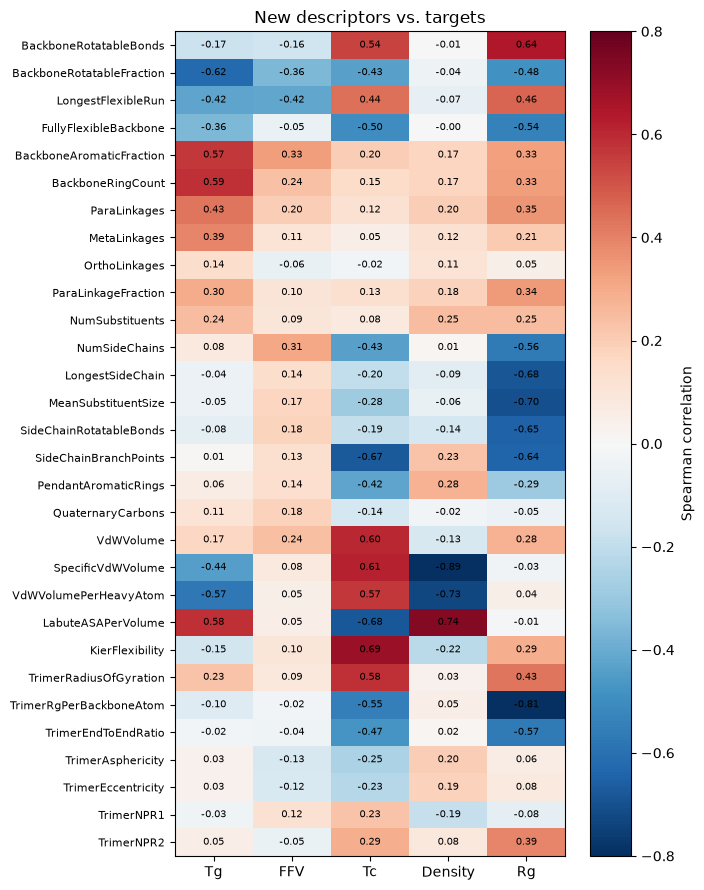

In [4]:
# Correlation of the new descriptors with the targets (Spearman, available labels only)
new_columns = CHAIN_COLUMNS + SHAPE_COLUMNS
new_features = pd.concat([chain_df, shape_df], axis=1)
correlations = pd.DataFrame({
    target: new_features[train[target].notna()].corrwith(
        train.loc[train[target].notna(), target], method="spearman")
    for target in target_columns
})

plt.figure(figsize=(7, 9))
plt.imshow(correlations, cmap="RdBu_r", vmin=-0.8, vmax=0.8, aspect="auto")
plt.colorbar(label="Spearman correlation")
plt.xticks(range(len(target_columns)), target_columns)
plt.yticks(range(len(new_columns)), new_columns, fontsize=8)
for i in range(len(new_columns)):
    for j in range(len(target_columns)):
        plt.text(j, i, f"{correlations.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.title("New descriptors vs. targets")
plt.tight_layout()
plt.show()

## 4. Splits and folds

The same splits and folds as in notebooks 04 and 05.

In [5]:
cv_folds = KFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
labels = train[target_columns].to_numpy(dtype=float)

train_rows, fold_rows = {}, {}
for target in target_columns:
    labelled = train.index[train[target].notna()]
    train_index, _ = train_test_split(
        labelled, test_size=VALIDATION_FRACTION, random_state=RANDOM_STATE, shuffle=True
    )
    train_rows[target] = np.asarray(train_index)
    fold_rows[target] = [train_rows[target][test_idx] for _, test_idx in cv_folds.split(train_index)]

expected_sizes = {"Tg": 408, "FFV": 5624, "Tc": 589, "Density": 490, "Rg": 491}
assert {t: len(rows) for t, rows in train_rows.items()} == expected_sizes

## 5. Do the chain descriptors help?

Three models are compared on every feature set:

- **Random forest** and **XGBoost** with the default settings of notebook 04
  (the random forest only on the sets without fingerprints, to save time),
- **Tuned XGBoost** with the best settings per target from notebook 04, section 24.
  These settings were chosen for B+ or B+ + D and are not re-tuned here.

The score is the **error reduction**: 1 − MAE / MAE of the median baseline of the
same fold (higher is better). R² is reported as well. This step takes about 20–30 minutes.

In [6]:
def create_default_xgboost():
    return XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=4, subsample=0.8,
                        colsample_bytree=0.8, random_state=RANDOM_STATE, n_jobs=-1)


def create_random_forest():
    return RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)


# Best tuned XGBoost settings per target (notebook 04, section 24)
tuned_params = {
    "Tg": dict(n_estimators=750, learning_rate=0.013339162948869679, max_depth=2,
               min_child_weight=1, subsample=0.6550083776583973,
               colsample_bytree=0.7394663949166917, reg_lambda=7.472397689332939),
    "FFV": dict(n_estimators=1464, learning_rate=0.013815607382950859, max_depth=8,
                min_child_weight=7, subsample=0.8034282764658811,
                colsample_bytree=0.610167650697638, reg_lambda=0.4253162363790871),
    "Tc": dict(n_estimators=708, learning_rate=0.013399060561509796, max_depth=5,
               min_child_weight=7, subsample=0.6693458614031088,
               colsample_bytree=0.7218455076693483, reg_lambda=4.638630972397279),
    "Density": dict(n_estimators=1464, learning_rate=0.013815607382950859, max_depth=8,
                    min_child_weight=7, subsample=0.8034282764658811,
                    colsample_bytree=0.610167650697638, reg_lambda=0.4253162363790871),
    "Rg": dict(n_estimators=1031, learning_rate=0.018187859051288217, max_depth=8,
               min_child_weight=4, subsample=0.9439761626945282,
               colsample_bytree=0.9140703845572055, reg_lambda=0.85807606199213),
}

models = {
    "Random forest": lambda target: create_random_forest(),
    "XGBoost (default)": lambda target: create_default_xgboost(),
    "XGBoost (tuned)": lambda target: XGBRegressor(**tuned_params[target],
                                                   random_state=RANDOM_STATE, n_jobs=-1),
}

result_rows = []
start = time.time()

for target_idx, target in enumerate(target_columns):
    for set_name, features in feature_sets.items():
        X_all = features.to_numpy(dtype=float)
        for model_name, create_model in models.items():
            if model_name == "Random forest" and set_name.endswith("D"):
                continue
            for fold in range(N_FOLDS):
                rows = fold_rows[target][fold]
                fit_rows = np.setdiff1d(train_rows[target], rows)
                y_fit, y_true = labels[fit_rows, target_idx], labels[rows, target_idx]

                pipeline = make_pipeline(SimpleImputer(strategy="median"), create_model(target))
                y_pred = pipeline.fit(X_all[fit_rows], y_fit).predict(X_all[rows])
                baseline_mae = np.mean(np.abs(y_true - np.median(y_fit)))

                result_rows.append({
                    "target": target, "feature_set": set_name, "model": model_name, "fold": fold,
                    "MAE": mean_absolute_error(y_true, y_pred),
                    "error_reduction": 100 * (1 - mean_absolute_error(y_true, y_pred) / baseline_mae),
                    "R2": r2_score(y_true, y_pred),
                })
    print(f"{target} done ({time.time() - start:.0f} s)")

results_df = pd.DataFrame(result_rows)

Tg done (18 s)


FFV done (118 s)


Tc done (142 s)


Density done (180 s)


Rg done (216 s)


In [7]:
set_order = list(feature_sets)

for value in ["error_reduction", "MAE", "R2"]:
    print(f"Mean {value} over the five folds")
    display(
        results_df.pivot_table(index=["target", "model"], columns="feature_set", values=value)
        .loc[target_columns, set_order].round(4 if value == "MAE" else 3 if value == "R2" else 1)
    )

Mean error_reduction over the five folds


feature_set                  B+  B+ + chain  B+ + chain + shape  B+ + D  \
target  model                                                             
Tg      Random forest      39.9        43.0                42.5     NaN   
        XGBoost (default)  40.4        41.9                42.9    41.1   
        XGBoost (tuned)    43.1        44.7                44.8    44.3   
FFV     Random forest      61.2        63.3                62.3     NaN   
        XGBoost (default)  60.6        63.8                63.3    66.1   
        XGBoost (tuned)    63.7        66.8                65.9    69.4   
Tc      Random forest      61.5        63.8                63.7     NaN   
        XGBoost (default)  62.5        64.5                64.0    65.7   
        XGBoost (tuned)    64.4        66.3                65.6    66.6   
Density Random forest      67.7        74.7                74.3     NaN   
        XGBoost (default)  70.5        78.1                77.6    72.0   
        XGBoost (tuned)    71.0        78.1                77.8    72.9   
Rg      Random forest      64.2        66.1                64.9     NaN   
        XGBoost (default)  64.8        66.7                66.3    64.6   
        XGBoost (tuned)    65.1        66.7                66.7    65.1   

feature_set                B+ + chain + shape + D  
target  model                                      
Tg      Random forest                         NaN  
        XGBoost (default)                    42.9  
        XGBoost (tuned)                      45.6  
FFV     Random forest                         NaN  
        XGBoost (default)                    67.6  
        XGBoost (tuned)                      70.4  
Tc      Random forest                         NaN  
        XGBoost (default)                    65.1  
        XGBoost (tuned)                      66.5  
Density Random forest                         NaN  
        XGBoost (default)                    77.4  
        XGBoost (tuned)                      78.6  
Rg      Random forest                         NaN  
        XGBoost (default)                    66.0  
        XGBoost (tuned)                      65.9

Mean MAE over the five folds


feature_set                     B+  B+ + chain  B+ + chain + shape   B+ + D  \
target  model                                                                 
Tg      Random forest      53.2257     50.4498             50.8823      NaN   
        XGBoost (default)  52.8323     51.4666             50.5912  52.1628   
        XGBoost (tuned)    50.3725     49.0390             48.9504  49.3249   
FFV     Random forest       0.0080      0.0076              0.0078      NaN   
        XGBoost (default)   0.0081      0.0075              0.0076   0.0070   
        XGBoost (tuned)     0.0075      0.0069              0.0070   0.0063   
Tc      Random forest       0.0290      0.0272              0.0273      NaN   
        XGBoost (default)   0.0282      0.0268              0.0271   0.0259   
        XGBoost (tuned)     0.0268      0.0254              0.0259   0.0252   
Density Random forest       0.0340      0.0265              0.0270      NaN   
        XGBoost (default)   0.0311      0.0231              0.0236   0.0294   
        XGBoost (tuned)     0.0306      0.0231              0.0234   0.0286   
Rg      Random forest       1.4007      1.3253              1.3740      NaN   
        XGBoost (default)   1.3768      1.3031              1.3161   1.3843   
        XGBoost (tuned)     1.3656      1.3004              1.3008   1.3651   

feature_set                B+ + chain + shape + D  
target  model                                      
Tg      Random forest                         NaN  
        XGBoost (default)                 50.5963  
        XGBoost (tuned)                   48.1637  
FFV     Random forest                         NaN  
        XGBoost (default)                  0.0067  
        XGBoost (tuned)                    0.0061  
Tc      Random forest                         NaN  
        XGBoost (default)                  0.0263  
        XGBoost (tuned)                    0.0252  
Density Random forest                         NaN  
        XGBoost (default)                  0.0238  
        XGBoost (tuned)                    0.0226  
Rg      Random forest                         NaN  
        XGBoost (default)                  1.3274  
        XGBoost (tuned)                    1.3327

Mean R2 over the five folds


feature_set                   B+  B+ + chain  B+ + chain + shape  B+ + D  \
target  model                                                              
Tg      Random forest      0.632       0.657               0.656     NaN   
        XGBoost (default)  0.637       0.643               0.660   0.641   
        XGBoost (tuned)    0.664       0.674               0.678   0.675   
FFV     Random forest      0.734       0.753               0.740     NaN   
        XGBoost (default)  0.741       0.763               0.753   0.788   
        XGBoost (tuned)    0.756       0.774               0.763   0.801   
Tc      Random forest      0.779       0.803               0.800     NaN   
        XGBoost (default)  0.798       0.811               0.804   0.813   
        XGBoost (tuned)    0.814       0.828               0.821   0.829   
Density Random forest      0.844       0.918               0.917     NaN   
        XGBoost (default)  0.849       0.930               0.927   0.874   
        XGBoost (tuned)    0.872       0.928               0.929   0.883   
Rg      Random forest      0.789       0.813               0.792     NaN   
        XGBoost (default)  0.802       0.828               0.820   0.789   
        XGBoost (tuned)    0.809       0.824               0.817   0.794   

feature_set                B+ + chain + shape + D  
target  model                                      
Tg      Random forest                         NaN  
        XGBoost (default)                   0.663  
        XGBoost (tuned)                     0.687  
FFV     Random forest                         NaN  
        XGBoost (default)                   0.797  
        XGBoost (tuned)                     0.807  
Tc      Random forest                         NaN  
        XGBoost (default)                   0.809  
        XGBoost (tuned)                     0.825  
Density Random forest                         NaN  
        XGBoost (default)                   0.925  
        XGBoost (tuned)                     0.931  
Rg      Random forest                         NaN  
        XGBoost (default)                   0.810  
        XGBoost (tuned)                     0.804

feature_set,B+,B+ + chain,B+ + chain + shape,B+ + D,B+ + chain + shape + D
target,,,,,
Tg,43.1,44.7,44.8,44.3,45.6
FFV,63.7,66.8,65.9,69.4,70.4
Tc,64.4,66.3,65.6,66.6,66.5
Density,71.0,78.1,77.8,72.9,78.6
Rg,65.1,66.7,66.7,65.1,66.0


Gain in percentage points


,chain vs. B+,chain + shape vs. B+,chain + shape + D vs. B+ + D,"fold std (B+ + D, best model)"
target,,,,
Tg,1.5,1.6,1.3,2.9
FFV,3.0,2.2,1.0,1.2
Tc,1.9,1.2,-0.1,3.1
Density,7.1,6.8,5.7,2.8
Rg,1.6,1.7,0.9,2.9


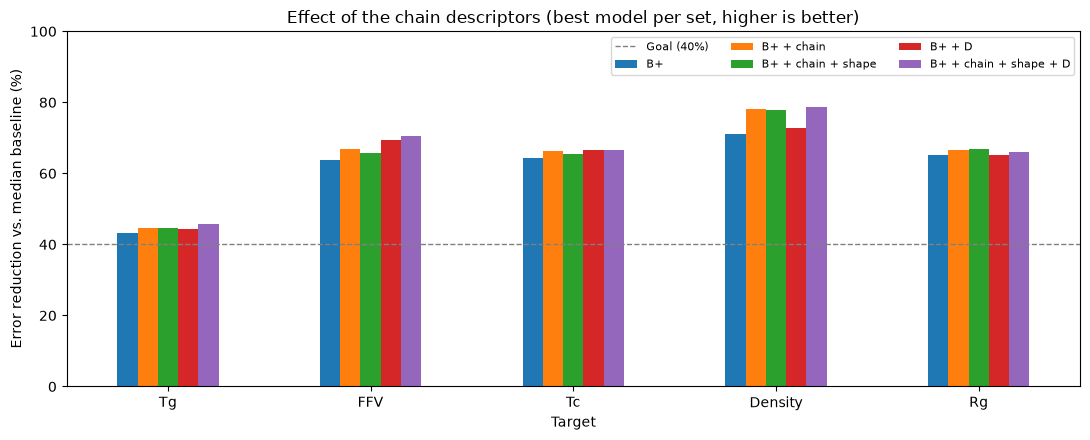

In [8]:
# Best model per target and feature set: error reduction
best_reduction = (
    results_df.groupby(["target", "feature_set", "model"])["error_reduction"].mean()
    .groupby(["target", "feature_set"]).max().unstack().loc[target_columns, set_order]
)
display(best_reduction.round(1))

# Change compared with the reference sets (B+ and B+ + D), in percentage points
print("Gain in percentage points")
display(pd.DataFrame({
    "chain vs. B+": best_reduction["B+ + chain"] - best_reduction["B+"],
    "chain + shape vs. B+": best_reduction["B+ + chain + shape"] - best_reduction["B+"],
    "chain + shape + D vs. B+ + D": best_reduction["B+ + chain + shape + D"] - best_reduction["B+ + D"],
    "fold std (B+ + D, best model)": results_df[results_df["feature_set"] == "B+ + D"]
        .groupby(["target", "model"])["error_reduction"].std().groupby("target").min(),
}).loc[target_columns].round(1))

ax = best_reduction.plot(kind="bar", figsize=(11, 4.5), rot=0)
ax.axhline(40, color="grey", linestyle="--", linewidth=1, label="Goal (40%)")
ax.set_ylim(0, 100)
ax.set_ylabel("Error reduction vs. median baseline (%)")
ax.set_xlabel("Target")
ax.set_title("Effect of the chain descriptors (best model per set, higher is better)")
ax.legend(fontsize=8, ncol=3)
plt.tight_layout()
plt.show()

## 6. Which new descriptors does the model use?

XGBoost with default settings is trained on B+ + chain + shape for each target
(training subsets only). The table lists the ten most important descriptors
(gain-based importance); new descriptors are marked with ★.

In [9]:
importance_rows = []
features = feature_sets["B+ + chain + shape"]

for target_idx, target in enumerate(target_columns):
    rows = train_rows[target]
    pipeline = make_pipeline(SimpleImputer(strategy="median"), create_default_xgboost())
    pipeline.fit(features.to_numpy(dtype=float)[rows], labels[rows, target_idx])
    importance = pd.Series(pipeline[-1].feature_importances_, index=features.columns)
    for rank, (feature, value) in enumerate(importance.nlargest(10).items(), start=1):
        marker = " ★" if feature in new_columns else ""
        importance_rows.append({"target": target, "rank": rank,
                                "feature": f"{feature}{marker} ({value:.2f})"})

display(pd.DataFrame(importance_rows).pivot(index="rank", columns="target", values="feature")[target_columns])

target,Tg,FFV,Tc,Density,Rg
rank,,,,,
1,BackboneRingCount ★ (0.29),BackboneRingFraction (0.10),NumRotatableBonds (0.24),SpecificVdWVolume ★ (0.46),TrimerRgPerBackboneAtom ★ (0.20)
2,FractionCSP3 (0.11),TPSAPerHeavyAtom (0.08),SideChainBranchPoints ★ (0.13),MolWtPerHeavyAtom (0.07),SideChainFraction (0.13)
3,BackboneRingFraction (0.08),SiliconCount (0.05),HalogenCount (0.07),VdWVolumePerHeavyAtom ★ (0.06),BackboneRingCount ★ (0.10)
4,BackboneRotatableFraction ★ (0.06),VdWVolumePerHeavyAtom ★ (0.05),KierFlexibility ★ (0.07),BackboneRingFraction (0.06),BackboneLength (0.06)
5,NumRings (0.05),HDonorsPerHeavyAtom (0.04),BackboneLength (0.06),LabuteASAPerVolume ★ (0.04),BackboneAromaticFraction ★ (0.06)
6,VdWVolumePerHeavyAtom ★ (0.03),LongestFlexibleRun ★ (0.04),SpecificVdWVolume ★ (0.03),MolLogPPerHeavyAtom (0.04),MeanSubstituentSize ★ (0.04)
7,LongestSideChain ★ (0.02),SiloxaneBackbone (0.04),BackboneAromaticFraction ★ (0.02),HAcceptorsPerHeavyAtom (0.03),BackboneRotatableFraction ★ (0.04)
8,HydroxylSideChain (0.02),BackboneAromaticFraction ★ (0.03),HAcceptorsPerHeavyAtom (0.02),TPSA (0.02),ParaLinkages ★ (0.03)
9,AmideBackbone (0.01),BackboneRotatableFraction ★ (0.03),EsterSideChain (0.02),TPSAPerHeavyAtom (0.02),LargestSideGroup (0.03)


#### Findings: chain descriptors

Best cross-validated error reduction per target (%, best of the three models, 5 folds):

| Target | B+ (43) | B+ + chain (66) | B+ + chain + shape (73) | B+ + D (1,067) | All + D (1,097) | Gain vs. previous best | Fold std |
|---|---:|---:|---:|---:|---:|---:|---:|
| Tg | 43.1 | 44.7 | 44.8 | 44.3 | **45.6** | +1.3 | 2.9 |
| FFV | 63.7 | 66.8 | 65.9 | 69.4 | **70.4** | +1.0 | 1.2 |
| Tc | 64.4 | 66.3 | 65.6 | **66.6** | 66.5 | ±0 | 3.1 |
| Density | 71.0 | 78.1 | 77.8 | 72.9 | **78.6** | **+5.7** | 2.8 |
| Rg | 65.1 | **66.7** | 66.7 | 65.1 | 66.0 | +1.6 | 2.9 |

- **Density improves clearly**: MAE 0.0286 → 0.0226 g/cm³ (−21%), R² 0.88 → 0.93.
  The gain is about twice the fold-to-fold variation. The model relies mainly on
  `SpecificVdWVolume` (importance 0.46): density is mass per volume, and the van der
  Waals volume per mass is the physical quantity behind it.
- **The chain descriptors replace much of the fingerprint information**: without
  fingerprints, they add 1.5–3 points for Tg, FFV, Tc and Rg. With fingerprints, the
  extra gain for these targets is 0–1.6 points, within the fold-to-fold variation.
- **The new descriptors are used in a chemically sensible way**:
  - Tg: `BackboneRingCount` is the most important descriptor (0.29), together with
    `BackboneRotatableFraction` and `LongestFlexibleRun` (backbone stiffness).
  - Tc: `SideChainBranchPoints` and `KierFlexibility` (chain flexibility and bulk).
  - Rg: `TrimerRgPerBackboneAtom`, the 3D shape descriptor, is the most important (0.20).
  - FFV: `VdWVolumePerHeavyAtom` and the backbone flexibility descriptors.
- **The 3D shape descriptors add little beyond the 2D chain descriptors** (−1 to +1 point),
  except as the top descriptor for Rg; one conformer of three units is a noisy picture.
  72 polymers (0.9%) have no conformer and are filled by the imputer.

Limitations: the tuned XGBoost settings were chosen in notebook 04 for B+ or B+ + D and
not re-tuned for the new sets; the validation subsets were not used.

**Decision:** the chain and shape descriptors are added to the feature set
(**all 73 descriptors + fingerprints** for Tg, FFV and Density; B+ + chain for Rg;
Tc unchanged). The next step is to rebuild the ensemble and the final validation
with the new features.

## 7. Ensemble with the new descriptors

Notebook 05 combined a multi-task network (on B+) with tuned XGBoost (on B+ or B+ + D)
as a 50/50 ensemble. The same ensemble is now rebuilt with the new descriptors and
compared with the old one on the same folds:

| | Old (notebook 05) | New |
|---|---|---|
| Multi-task network | B+ (43 descriptors) | B+ + chain + shape (73 descriptors) |
| Tree model | tuned XGBoost, B+ + D (Rg: B+) | best model and feature set per target from section 5 (lowest MAE) |
| Ensemble | 50/50 average | 50/50 average |

- The network settings and seeds are the same as in notebook 05
  (`src/multitask_network.py`), so the old models reproduce notebook 05.
- The XGBoost settings are **not re-tuned**; only the features change.
- For each target, the new final model is the one of the three new candidates
  (network, tree model, ensemble) with the **lowest cross-validated MAE**.
  This choice is made before the validation subsets are scored.

In [10]:
import torch

from src.multitask_network import fit_network

torch.set_num_threads(8)

# Old tree model per target: tuned XGBoost with the feature set from notebook 04, section 24
old_tree = {target: ("B+ + D", "XGBoost (tuned)") for target in target_columns}
old_tree["Rg"] = ("B+", "XGBoost (tuned)")

# New tree model per target: lowest mean MAE in section 5
mean_mae = results_df.groupby(["target", "feature_set", "model"])["MAE"].mean()
new_tree = {target: mean_mae.loc[target].idxmin() for target in target_columns}
display(pd.DataFrame(
    {"old tree model": {t: f"{m} on {s}" for t, (s, m) in old_tree.items()},
     "new tree model": {t: f"{m} on {s}" for t, (s, m) in new_tree.items()}}
).loc[target_columns])

network_sets = {"old": "B+", "new": "B+ + chain + shape"}


def fit_tree(target, choice, fit_rows, y_fit):
    set_name, model_name = choice
    X_set = feature_sets[set_name].to_numpy(dtype=float)
    pipeline = make_pipeline(SimpleImputer(strategy="median"), models[model_name](target))
    pipeline.fit(X_set[fit_rows], y_fit)
    return lambda rows: pipeline.predict(X_set[rows])


def candidate_predictions(networks, target_idx, target, fit_rows, y_fit, rows):
    predictions = {}
    for version, trees in [("Old", old_tree), ("New", new_tree)]:
        X_network = feature_sets[network_sets[version.lower()]].to_numpy(dtype=float)
        network_pred = networks[version.lower()](X_network[rows])[:, target_idx]
        tree_pred = fit_tree(target, trees[target], fit_rows, y_fit)(rows)
        predictions[f"{version} network"] = network_pred
        predictions[f"{version} tree model"] = tree_pred
        predictions[f"{version} ensemble"] = (network_pred + tree_pred) / 2
    return predictions


def fit_networks(Y, seed):
    has_label = ~np.isnan(Y).all(axis=1)
    return {
        version: fit_network(feature_sets[set_name].to_numpy(dtype=float)[has_label],
                             Y[has_label], seed=seed)
        for version, set_name in network_sets.items()
    }


ensemble_rows = []
start = time.time()

for fold in range(N_FOLDS):
    Y_fold = np.full_like(labels, np.nan)
    for t, target in enumerate(target_columns):
        fit_rows = np.setdiff1d(train_rows[target], fold_rows[target][fold])
        Y_fold[fit_rows, t] = labels[fit_rows, t]

    # Same seeds as notebook 05, section 7
    networks = fit_networks(Y_fold, seed=RANDOM_STATE + fold)

    for t, target in enumerate(target_columns):
        rows = fold_rows[target][fold]
        fit_rows = np.flatnonzero(~np.isnan(Y_fold[:, t]))
        y_fit, y_true = Y_fold[fit_rows, t], labels[rows, t]
        baseline_mae = np.mean(np.abs(y_true - np.median(y_fit)))

        predictions = candidate_predictions(networks, t, target, fit_rows, y_fit, rows)
        for model_name, y_pred in predictions.items():
            mae = mean_absolute_error(y_true, y_pred)
            ensemble_rows.append({"target": target, "model": model_name, "fold": fold,
                                  "MAE": mae, "error_reduction": 100 * (1 - mae / baseline_mae),
                                  "R2": r2_score(y_true, y_pred)})

    print(f"Fold {fold + 1} done ({time.time() - start:.0f} s)")

ensemble_df = pd.DataFrame(ensemble_rows)

,old tree model,new tree model
Tg,XGBoost (tuned) on B+ + D,XGBoost (tuned) on B+ + chain + shape + D
FFV,XGBoost (tuned) on B+ + D,XGBoost (tuned) on B+ + chain + shape + D
Tc,XGBoost (tuned) on B+ + D,XGBoost (tuned) on B+ + D
Density,XGBoost (tuned) on B+ + D,XGBoost (tuned) on B+ + chain + shape + D
Rg,XGBoost (tuned) on B+,XGBoost (tuned) on B+ + chain


Fold 1 done (34 s)


Fold 2 done (61 s)


Fold 3 done (85 s)


Fold 4 done (112 s)


Fold 5 done (136 s)


In [11]:
candidate_order = ["Old network", "Old tree model", "Old ensemble",
                   "New network", "New tree model", "New ensemble"]

for value in ["error_reduction", "MAE", "R2"]:
    print(f"Cross-validated {value} (mean over 5 folds)")
    display(ensemble_df.pivot_table(index="target", columns="model", values=value)
            .loc[target_columns, candidate_order].round(4 if value == "MAE" else 3 if value == "R2" else 1))

# Old final models (notebook 05): ensemble, but tuned XGBoost for FFV
old_final = {target: "Old ensemble" for target in target_columns}
old_final["FFV"] = "Old tree model"

# New final models: the new candidate with the lowest cross-validated MAE
cv_mae = ensemble_df.groupby(["target", "model"])["MAE"].mean().unstack()
new_final = {target: cv_mae.loc[target, candidate_order[3:]].idxmin() for target in target_columns}

cv_reduction = ensemble_df.groupby(["target", "model"])["error_reduction"].agg(["mean", "std"])
cv_comparison = pd.DataFrame({
    "old final model": old_final,
    "old error reduction": {t: cv_reduction.loc[(t, m), "mean"] for t, m in old_final.items()},
    "new final model": new_final,
    "new error reduction": {t: cv_reduction.loc[(t, m), "mean"] for t, m in new_final.items()},
    "fold std (new)": {t: cv_reduction.loc[(t, m), "std"] for t, m in new_final.items()},
}).loc[target_columns]
cv_comparison["gain (points)"] = cv_comparison["new error reduction"] - cv_comparison["old error reduction"]
display(cv_comparison.round(1))

Cross-validated error_reduction (mean over 5 folds)


model,Old network,Old tree model,Old ensemble,New network,New tree model,New ensemble
target,,,,,,
Tg,43.1,44.3,46.7,41.2,45.6,45.9
FFV,57.3,69.4,66.2,61.7,70.4,68.3
Tc,63.9,66.6,66.8,64.5,66.6,67.1
Density,69.6,72.9,73.6,74.0,78.6,78.3
Rg,63.3,65.1,66.6,65.3,66.7,68.5


Cross-validated MAE (mean over 5 folds)


model,Old network,Old tree model,Old ensemble,New network,New tree model,New ensemble
target,,,,,,
Tg,50.4829,49.3249,47.2017,52.1187,48.1637,47.9336
FFV,0.0088,0.0063,0.0070,0.0079,0.0061,0.0065
Tc,0.0271,0.0252,0.0250,0.0268,0.0252,0.0247
Density,0.0316,0.0286,0.0276,0.0268,0.0226,0.0227
Rg,1.4338,1.3656,1.3041,1.3564,1.3004,1.2333


Cross-validated R2 (mean over 5 folds)


model,Old network,Old tree model,Old ensemble,New network,New tree model,New ensemble
target,,,,,,
Tg,0.656,0.675,0.694,0.630,0.687,0.689
FFV,0.718,0.801,0.784,0.744,0.807,0.795
Tc,0.806,0.829,0.833,0.830,0.829,0.845
Density,0.843,0.883,0.886,0.903,0.931,0.928
Rg,0.772,0.809,0.815,0.823,0.824,0.844


,old final model,old error reduction,new final model,new error reduction,fold std (new),gain (points)
Tg,Old ensemble,46.7,New ensemble,45.9,2.3,-0.8
FFV,Old tree model,69.4,New tree model,70.4,1.3,1.0
Tc,Old ensemble,66.8,New ensemble,67.1,3.7,0.4
Density,Old ensemble,73.6,New tree model,78.6,2.6,5.0
Rg,Old ensemble,66.6,New ensemble,68.5,2.0,1.8


## 8. Final evaluation on the validation subsets

The new final models are trained once on the complete training subsets and scored
once on the validation subsets, together with the old final models from notebook 05,
the starting model (random forest on the nine original descriptors) and the median
baseline.

Note: the validation subsets were already used once, in notebook 05, to score the old
final models. Nothing in this notebook was chosen with them (all choices above use
cross-validation only), but they are no longer completely untouched.

**From here on, the validation subsets are frozen.** All further tuning and model
choices use cross-validation only. The validation subsets are scored exactly once
more, at the very end, for the final model next to the starting model.

In [12]:
from sklearn.dummy import DummyRegressor

valid_rows = {
    target: np.setdiff1d(train.index[train[target].notna()], train_rows[target])
    for target in target_columns
}

# Networks trained on all training labels (validation labels masked), seed as in notebook 05
Y_train = np.full_like(labels, np.nan)
for t, target in enumerate(target_columns):
    Y_train[train_rows[target], t] = labels[train_rows[target], t]
networks = fit_networks(Y_train, seed=RANDOM_STATE)

X_original = bplus_df.iloc[:, :9].to_numpy(dtype=float)

valid_results = []
valid_predictions = {}
for t, target in enumerate(target_columns):
    fit_rows, rows = train_rows[target], valid_rows[target]
    y_fit, y_true = labels[fit_rows, t], labels[rows, t]

    starting_model = create_random_forest().fit(X_original[fit_rows], y_fit)
    candidates = candidate_predictions(networks, t, target, fit_rows, y_fit, rows)
    predictions = {
        "Median baseline": np.full(len(rows), np.median(y_fit)),
        "Starting model": starting_model.predict(X_original[rows]),
        "Old final model": candidates[old_final[target]],
        "New final model": candidates[new_final[target]],
    }
    valid_predictions[target] = (y_true, predictions["New final model"])

    baseline_mae = mean_absolute_error(y_true, predictions["Median baseline"])
    for model_name, y_pred in {**predictions, **candidates}.items():
        mae = mean_absolute_error(y_true, y_pred)
        valid_results.append({"target": target, "model": model_name, "MAE": mae,
                              "error_reduction": 100 * (1 - mae / baseline_mae),
                              "R2": r2_score(y_true, y_pred)})

valid_df = pd.DataFrame(valid_results)
summary_order = ["Median baseline", "Starting model", "Old final model", "New final model"]

print("Validation MAE")
display(valid_df.pivot(index="target", columns="model", values="MAE")
        .loc[target_columns, summary_order + candidate_order].round(4))
print("Validation error reduction vs. median baseline (%)")
display(valid_df.pivot(index="target", columns="model", values="error_reduction")
        .loc[target_columns, summary_order[1:] + candidate_order].round(1))
print("Validation R²")
display(valid_df.pivot(index="target", columns="model", values="R2")
        .loc[target_columns, summary_order[1:]].round(3))

Validation MAE


model,Median baseline,Starting model,Old final model,New final model,Old network,Old tree model,Old ensemble,New network,New tree model,New ensemble
target,,,,,,,,,,
Tg,78.7083,62.5781,52.8012,52.3752,55.0352,53.6190,52.8012,55.2195,54.6754,52.3752
FFV,0.0214,0.0109,0.0063,0.0062,0.0083,0.0063,0.0067,0.0071,0.0062,0.0062
Tc,0.0801,0.0393,0.0246,0.0227,0.0253,0.0263,0.0246,0.0228,0.0263,0.0227
Density,0.1044,0.0661,0.0277,0.0265,0.0327,0.0272,0.0277,0.0280,0.0265,0.0251
Rg,3.8640,2.8721,1.4572,1.3487,1.6510,1.5017,1.4572,1.5149,1.4384,1.3487


Validation error reduction vs. median baseline (%)


model,Starting model,Old final model,New final model,Old network,Old tree model,Old ensemble,New network,New tree model,New ensemble
target,,,,,,,,,
Tg,20.5,32.9,33.5,30.1,31.9,32.9,29.8,30.5,33.5
FFV,49.0,70.7,70.9,61.1,70.7,68.5,66.7,70.9,71.1
Tc,50.9,69.3,71.7,68.3,67.1,69.3,71.5,67.1,71.7
Density,36.7,73.5,74.6,68.7,73.9,73.5,73.2,74.6,76.0
Rg,25.7,62.3,65.1,57.3,61.1,62.3,60.8,62.8,65.1


Validation R²


model,Starting model,Old final model,New final model
target,,,
Tg,0.372,0.534,0.498
FFV,0.532,0.726,0.721
Tc,0.644,0.820,0.832
Density,0.349,0.798,0.738
Rg,0.237,0.755,0.784


,new final model,unit,baseline MAE,old final MAE,new final MAE,MAE change (%),old error reduction,new error reduction,new CV error reduction
Tg,New ensemble,°C,78.7083,52.8012,52.3752,-0.8069,32.9153,33.4565,45.9027
FFV,New tree model,–,0.0214,0.0063,0.0062,-0.6845,70.7256,70.9260,70.4052
Tc,New ensemble,W/(m·K),0.0801,0.0246,0.0227,-7.5973,69.3244,71.6549,67.1218
Density,New tree model,g/cm³,0.1044,0.0277,0.0265,-4.3900,73.4784,74.6427,78.5871
Rg,New ensemble,Å,3.8640,1.4572,1.3487,-7.4467,62.2867,65.0951,68.4537


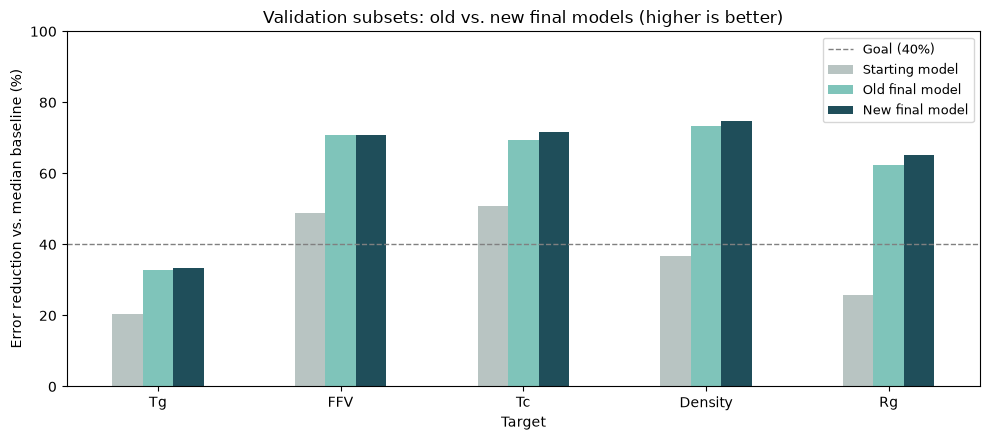

In [13]:
units = {"Tg": "°C", "FFV": "–", "Tc": "W/(m·K)", "Density": "g/cm³", "Rg": "Å"}
valid_mae = valid_df.pivot(index="target", columns="model", values="MAE")
valid_reduction = valid_df.pivot(index="target", columns="model", values="error_reduction")

final_summary = pd.DataFrame({
    "new final model": new_final,
    "unit": units,
    "baseline MAE": valid_mae["Median baseline"],
    "old final MAE": valid_mae["Old final model"],
    "new final MAE": valid_mae["New final model"],
    "MAE change (%)": 100 * (valid_mae["New final model"] / valid_mae["Old final model"] - 1),
    "old error reduction": valid_reduction["Old final model"],
    "new error reduction": valid_reduction["New final model"],
    "new CV error reduction": cv_comparison["new error reduction"],
}).loc[target_columns]
display(final_summary.round(4))

ax = valid_reduction.loc[target_columns, ["Starting model", "Old final model", "New final model"]].plot(
    kind="bar", figsize=(10, 4.5), rot=0, color=["#b8c4c2", "#7fc4ba", "#1f4e5a"])
ax.axhline(40, color="grey", linestyle="--", linewidth=1, label="Goal (40%)")
ax.set_ylim(0, 100)
ax.set_ylabel("Error reduction vs. median baseline (%)")
ax.set_xlabel("Target")
ax.set_title("Validation subsets: old vs. new final models (higher is better)")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

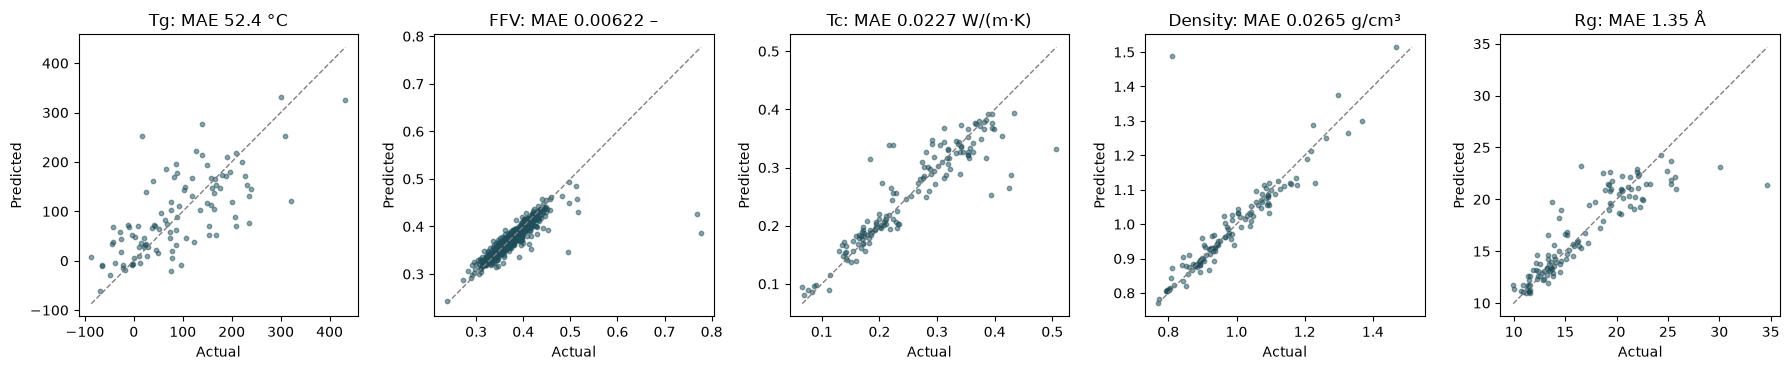

In [14]:
# Predicted vs. actual values of the new final models on the validation subsets
fig, axes = plt.subplots(1, 5, figsize=(18, 3.8))
for ax, target in zip(axes, target_columns):
    y_true, y_pred = valid_predictions[target]
    ax.scatter(y_true, y_pred, s=10, alpha=0.5, color="#1f4e5a")
    limits = [min(y_true.min(), y_pred.min()), max(y_true.max(), y_pred.max())]
    ax.plot(limits, limits, color="grey", linestyle="--", linewidth=1)
    ax.set_title(f"{target}: MAE {mean_absolute_error(y_true, y_pred):.3g} {units[target]}")
    ax.set_xlabel("Actual")
    ax.set_ylabel("Predicted")
plt.tight_layout()
plt.show()

#### Findings: ensemble and final evaluation with the new descriptors

The old models reproduce notebook 05 exactly (e.g. validation MAE Tg 52.8 °C, Rg 1.46 Å).

**Cross-validation** (error reduction vs. median baseline, %):

| Target | Old final model | New final model | Gain (points) | Fold std |
|---|---|---|---:|---:|
| Tg | ensemble: 46.7 | ensemble: 45.9 | −0.8 | 2.3 |
| FFV | XGBoost: 69.4 | XGBoost: 70.4 | +1.0 | 1.3 |
| Tc | ensemble: 66.8 | ensemble: 67.1 | +0.4 | 3.7 |
| Density | ensemble: 73.6 | **XGBoost: 78.6** | **+5.0** | 2.6 |
| Rg | ensemble: 66.6 | **ensemble: 68.5** | +1.8 | 2.0 |

**Validation subsets** (MAE):

| Target | Unit | Median baseline | Starting model | Old final model | **New final model** | MAE change | Error reduction (old → new) |
|---|---|---:|---:|---:|---:|---:|---:|
| Tg | °C | 78.7 | 62.6 | 52.8 | **52.4** | −1% | 33% → 33% |
| FFV | – | 0.0214 | 0.0109 | 0.0063 | **0.0062** | −1% | 71% → 71% |
| Tc | W/(m·K) | 0.080 | 0.039 | 0.0246 | **0.0227** | −8% | 69% → 72% |
| Density | g/cm³ | 0.104 | 0.066 | 0.0277 | **0.0265** | −4% | 73% → 75% |
| Rg | Å | 3.86 | 2.87 | 1.46 | **1.35** | −7% | 62% → 65% |

- **The new final models have a lower validation MAE for all five targets**, by 1% (Tg, FFV)
  to 7–8% (Tc, Rg). The direction is consistent, but each validation subset has only
  about 100–120 polymers (FFV: about 1,400), so differences of a few percent are within noise.
- **Density:** the clear gain in cross-validation (+5 points, R² 0.89 → 0.93) is only
  partly confirmed on the validation subset (MAE −4%), and the validation R² even falls
  (0.80 → 0.74). The lower MAE with a lower R² means that most predictions improve but
  a few polymers get larger errors; this should be checked before claiming the density gain.
- **Tc and Rg:** the network on the 73 descriptors is clearly better than on B+, and the
  ensemble improves by 3 points on the validation subsets.
- **Tg** stays the weakest property (33% error reduction, ±52 °C); the new descriptors
  do not change it.
- The 40% goal is still reached for FFV, Tc, Density and Rg, not for Tg.

Limitations: the XGBoost settings were not re-tuned for the new features; the validation
subsets were already used once in notebook 05, so they are no longer fully untouched.

**Decision:** the new final models replace the old ones (ensemble for Tg, Tc and Rg,
tuned XGBoost for FFV and Density; chosen by cross-validated MAE before the validation check).